In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("/content/haberman.csv")
print(df.head())
print(df.tail())
print(df.shape)
df.info()
print(df.describe())

   age  operation_year  positive_axillary_nodes  survival_status
0   30              64                        1                1
1   30              62                        3                1
2   30              65                        0                1
3   31              59                        2                1
4   31              65                        4                1
     age  operation_year  positive_axillary_nodes  survival_status
301   75              62                        1                1
302   76              67                        0                1
303   77              65                        3                1
304   78              65                        1                2
305   83              58                        2                2
(306, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 306 entries, 0 to 305
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   -------------

In [3]:
#Q.1 : Count records in each survival-status category
print(df["survival_status"].value_counts())

survival_status
1    225
2     81
Name: count, dtype: int64


In [5]:
#Q.2 : Find average, median, minimum and maximum age
age = df["age"].to_numpy()
print(f"Mean:   {np.mean(age)}")
print(f"Median: {np.median(age)}")
print(f"Min:    {np.min(age)}")
print(f"Max:    {np.max(age)}")

Mean:   52.45751633986928
Median: 52.0
Min:    30
Max:    83


In [8]:
#Q.3 : Find the average number of positive axillary nodes
nodes = df["positive_axillary_nodes"].to_numpy()
print(f"Mean nodes: {np.mean(nodes)}")

Mean nodes: 4.026143790849673


In [10]:
#Q.4 : Compare average age and node counts across the two status groups
group = df.groupby("survival_status")[["age", "positive_axillary_nodes"]].agg(["mean", "median"]).round(2)
print(group)

                   age        positive_axillary_nodes       
                  mean median                    mean median
survival_status                                             
1                52.02   52.0                    2.79    0.0
2                53.68   53.0                    7.46    4.0


In [13]:
#Q.5 :  Which operation years have the most records?
year_counts = df["operation_year"].value_counts().sort_values(ascending=False)
print((year_counts.head(5)))

operation_year
58    36
64    31
63    30
65    28
66    28
Name: count, dtype: int64


In [14]:
#Q.6 : Check for missing values and duplicates. Use the UCI data description to label columns if needed
print(df.isnull().sum())
dup_count = df.duplicated().sum()
print(f"\nDuplicate rows: {dup_count}")

age                        0
operation_year             0
positive_axillary_nodes    0
survival_status            0
dtype: int64

Duplicate rows: 17


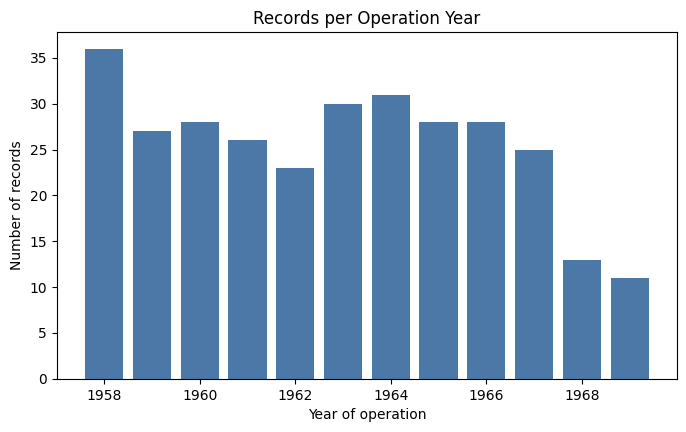

In [16]:
# Chart 1: bar chart of records per operation year
fig, ax = plt.subplots(figsize=(8, 4.5))
yc = df["operation_year"].value_counts().sort_index()
ax.bar(yc.index + 1900, yc.values, color="#4C78A8")
ax.set_xlabel("Year of operation")
ax.set_ylabel("Number of records")
ax.set_title("Records per Operation Year")
plt.show()

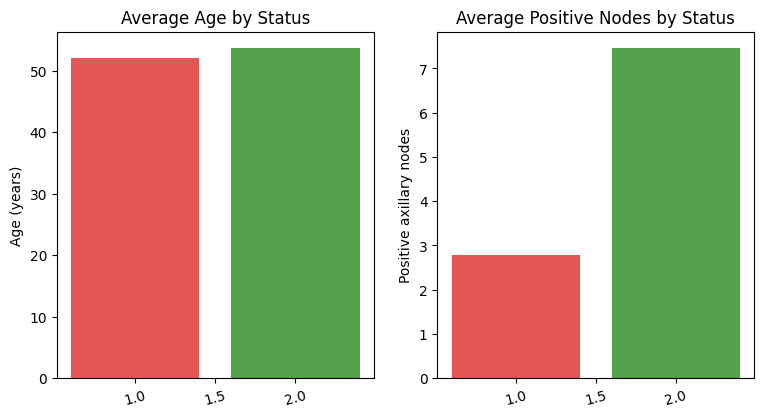

In [20]:
# Chart 2: average age and nodes by survival status
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
means = df.groupby("survival_status")[["age", "positive_axillary_nodes"]].mean()
colors = ["#E45756", "#54A24B"]
axes[0].bar(means.index, means["age"], color=colors)
axes[0].set_title("Average Age by Status")
axes[0].set_ylabel("Age (years)")
axes[1].bar(means.index, means["positive_axillary_nodes"], color=colors)
axes[1].set_title("Average Positive Nodes by Status")
axes[1].set_ylabel("Positive axillary nodes")
for a in axes:
    a.tick_params(axis="x", labelrotation=15)
plt.show()

In [21]:
# Filtering example: patients with zero nodes
zero = df[df["positive_axillary_nodes"] == 0]
print(f"\nRecords with 0 positive nodes: {len(zero)} ({len(zero)/len(df):.1%})")
print("Top 5 highest node counts:")
print(df.sort_values("positive_axillary_nodes", ascending=False).head(5))


Records with 0 positive nodes: 136 (44.4%)
Top 5 highest node counts:
     age  operation_year  positive_axillary_nodes  survival_status
62    43              58                       52                2
174   54              67                       46                1
215   59              62                       35                2
9     34              58                       30                1
252   63              61                       28                1


In [22]:
#Three Observations :
'''
1.The classes are imbalanced. About 73.5% of records (225 of 306) are in the survived-5-years-or-longer group and about 26.5% (81) are in the other group.
2.Node counts are heavily right-skewed. The mean (4.03) is far above the median (1), and nearly half of the records have no positive nodes. A few high values, up to 52, pull the average up, so the median describes a typical record better.
3.Node counts differ more between groups than age does. The died-within-5-years group has a higher average node count (7.46 vs 2.79), while average age differs by under 2 years (53.7 vs 52.0). This is only a descriptive comparison of this dataset and does not support any prediction or medical conclusion.
'''

'\n1.The classes are imbalanced. About 73.5% of records (225 of 306) are in the survived-5-years-or-longer group and about 26.5% (81) are in the other group.\n2.Node counts are heavily right-skewed. The mean (4.03) is far above the median (1), and nearly half of the records have no positive nodes. A few high values, up to 52, pull the average up, so the median describes a typical record better.\n3.Node counts differ more between groups than age does. The died-within-5-years group has a higher average node count (7.46 vs 2.79), while average age differs by under 2 years (53.7 vs 52.0). This is only a descriptive comparison of this dataset and does not support any prediction or medical conclusion.\n'